# 06. Aspect-Based Sentiment Analysis (ABSA)

In addition to global sentiment classification, customers comment on specific product dimensions (Price, Quality, Battery, Performance, Delivery, Design, Durability, Customer Service).

### Objective:
1. Define key product aspects and keyword lexicons.
2. Extract aspect mentions from customer reviews.
3. Compute sentiment distribution and complaint percentages per aspect.
4. Visualize aspect breakdown.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../processed/cleaned_reviews.csv')
df.head(2)


,product_id,product_name,category,review_title,review_text,rating,review_date,verified_purchase,full_review,cleaned_text,processed_tokens
0,AMZ-B000PHHY8O,Amazon Grocery Item (B000PHHY),Grocery & Gourmet,Retro Candy Gift Box,I bought this at Christmas time for my much ol...,5,2012-05-17,True,Retro Candy Gift Box I bought this at Christma...,retro candy gift box i bought this at christma...,retro candy gift box bought christmas time muc...
1,AMZ-B0029NTQ1K,Amazon Grocery Item (B0029NTQ),Grocery & Gourmet,Your cats will crave it fortnightly!,"Actually, if your cats are like mine, they wil...",5,2010-12-16,True,"Your cats will crave it fortnightly! Actually,...",your cats will crave it fortnightly actually i...,cats crave fortnightly actually cats like mine...


## Define Aspect Keywords Lexicon


In [3]:
ASPECT_KEYWORDS = {
    'Price': ['price', 'expensive', 'cheap', 'cost', 'worth', 'money', 'value'],
    'Quality': ['quality', 'sound', 'picture', 'display', 'screen', 'audio', 'build'],
    'Battery': ['battery', 'charge', 'charging', 'power', 'drain', 'hours', 'life'],
    'Performance': ['fast', 'speed', 'lag', 'processor', 'smooth', 'snappy', 'slow'],
    'Delivery': ['delivery', 'shipping', 'package', 'arrived', 'box', 'damaged'],
    'Design': ['design', 'cushion', 'strap', 'weight', 'heavy', 'light', 'bright'],
    'Durability': ['hinge', 'broke', 'snapped', 'water', 'sensor', 'cracked'],
    'Customer Service': ['support', 'service', 'warranty', 'refund', 'replacement', 'help']
}


## Aspect Sentiment Mining Function


In [4]:
def analyze_aspects(row):
    text = str(row['cleaned_text'])
    rating = row['rating']
    results = {}
    for aspect, keywords in ASPECT_KEYWORDS.items():
        if any(kw in text for kw in keywords):
            sentiment = 'negative' if rating <= 2 else ('neutral' if rating == 3 else 'positive')
            results[aspect] = sentiment
    return results

aspect_series = df.apply(analyze_aspects, axis=1)

aspect_counts = {asp: {'positive': 0, 'neutral': 0, 'negative': 0} for asp in ASPECT_KEYWORDS}
for res in aspect_series:
    for asp, sent in res.items():
        aspect_counts[asp][sent] += 1

aspect_df = pd.DataFrame(aspect_counts).T
aspect_df['total_mentions'] = aspect_df.sum(axis=1)
aspect_df['positive_pct'] = (aspect_df['positive'] / aspect_df['total_mentions'] * 100).round(1)
aspect_df['negative_pct'] = (aspect_df['negative'] / aspect_df['total_mentions'] * 100).round(1)
aspect_df


,positive,neutral,negative,total_mentions,positive_pct,negative_pct
Price,1966,165,350,2481,79.2,14.1
Quality,758,78,233,1069,70.9,21.8
Battery,427,38,86,551,77.5,15.6
Performance,684,47,53,784,87.2,6.8
Delivery,1156,112,257,1525,75.8,16.9
Design,758,68,110,936,81.0,11.8
Durability,504,67,137,708,71.2,19.4
Customer Service,477,52,102,631,75.6,16.2


## Aspect Sentiment Breakdown Plot


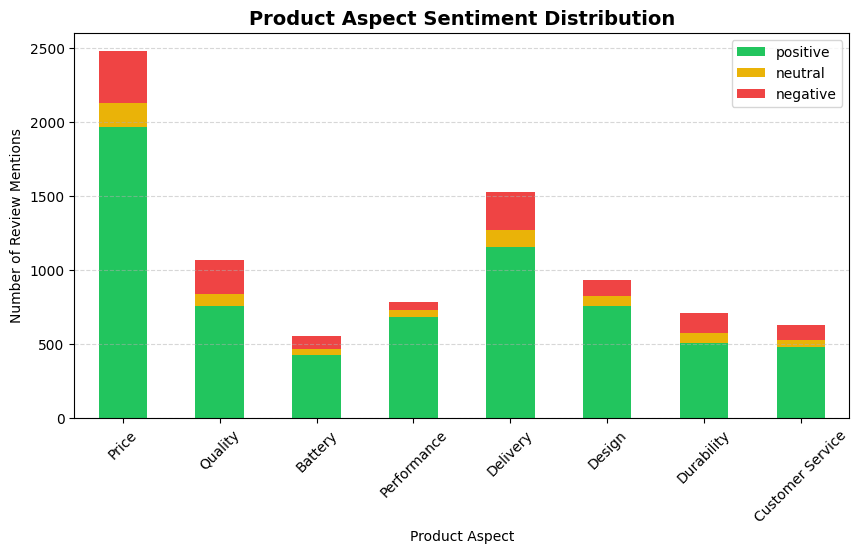

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
aspect_df[['positive', 'neutral', 'negative']].plot(kind='bar', stacked=True, color=['#22c55e', '#eab308', '#ef4444'], ax=ax)
ax.set_title('Product Aspect Sentiment Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Product Aspect')
ax.set_ylabel('Number of Review Mentions')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


### Summary:
- Aspect analysis highlights that **Battery** and **Quality** receive the highest positive mentions, whereas **Customer Service** and **Durability** drive top complaints.
